
# TFG — Valoración Monte Carlo de una **opción call americana con dividendos** bajo **volatilidad con cambio de régimen**
## Implementación completa (y “seguible”) de:
- Simulación Monte Carlo del subyacente con **regímenes Markovianos** en la volatilidad  
- Algoritmo **Longstaff–Schwartz (LSMC)** para ejercicio óptimo (americana)  
- **Validación** (benchmark binomial en caso sin regímenes + diagnósticos in/out-of-sample)  
- Reducción de varianza con **Importance Sampling** (cambio de medida + likelihood ratio)

> **Objetivo del notebook:** que puedas enseñar el código y el flujo *paso a paso* en el TFG:  
> 1) matriz \(S_{t_n}\) → 2) payoffs → 3) regla de paro (stop/continue) → 4) cashflows descontados → 5) promedio → 6) validación.

---

### Notación (la que usamos en todo el notebook)

Bajo medida neutral al riesgo, con **dividend yield continuo** \(q\):

\[
dS_t=(r-q)S_t\,dt+\sigma(X_t)S_t\,dW_t
\]

Regímenes \(X_t \in \{1,2,\dots,R\}\) con transición Markoviana discreta en la malla \(t_0,\dots,t_N\):

\[
\mathbb P(X_{n+1}=j\mid X_n=i)=P_{ij}
\]

Discretización (Euler exacto para GBM condicional a \(\sigma\) constante en \([t_n,t_{n+1}]\)):

\[
S_{n+1}=S_n\exp\left(\left(r-q-\tfrac12\sigma^2(X_n)\right)\Delta t+\sigma(X_n)\sqrt{\Delta t}\,Z_{n+1}\right),\quad Z\sim\mathcal N(0,1)
\]

Payoff de la **call**: \(\Phi(S)=\max(S-K,0)\).

---

### Estructura del notebook
1. Imports y utilidades
2. Simulación de trayectorias con cambio de régimen
3. LSMC (Longstaff–Schwartz) — implementación **fiel al ejemplo** del paper
4. Resultados intermedios: matrices, regresiones, decisiones stop/continue
5. Validación: binomial (sin regímenes) + estabilidad in/out-of-sample
6. Importance Sampling: teoría mínima + implementación práctica + comparación de varianza


In [3]:

# 1) Imports y configuración
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)

def set_seed(seed: int = 123):
    return np.random.default_rng(seed)

print("OK — imports cargados")


OK — imports cargados



## 1.1. Utilidades: validación de parámetros y helpers
En un TFG merece la pena ser explícito con:
- validación de shapes,
- checks de matriz de transición estocástica,
- manejo reproducible del RNG,
- y funciones auxiliares para mostrar resultados intermedios.


In [4]:

from dataclasses import dataclass

@dataclass(frozen=True)
class RegimeParams:
    sigmas: np.ndarray   # (R,) volatilidades por régimen
    P: np.ndarray        # (R,R) matriz de transición (filas suman 1)

@dataclass(frozen=True)
class MarketParams:
    r: float             # tipo libre de riesgo
    q: float             # dividend yield continuo

def validate_params(regime: RegimeParams, market: MarketParams):
    sigmas = np.asarray(regime.sigmas, dtype=float)
    P = np.asarray(regime.P, dtype=float)

    if sigmas.ndim != 1:
        raise ValueError("sigmas debe ser un vector 1D (R,).")
    if np.any(sigmas <= 0):
        raise ValueError("todas las sigmas deben ser > 0.")
    R = sigmas.shape[0]

    if P.shape != (R, R):
        raise ValueError(f"P debe tener shape ({R},{R}).")
    if np.any(P < 0):
        raise ValueError("P no puede tener entradas negativas.")
    if not np.allclose(P.sum(axis=1), 1.0, atol=1e-12):
        raise ValueError("Cada fila de P debe sumar 1 (matriz estocástica por filas).")

    if market.r < 0:
        raise ValueError("r debe ser >= 0 (o al menos no negativo en este notebook).")
    if market.q < 0:
        raise ValueError("q debe ser >= 0 (dividend yield continuo).")

    return True

def discount_factor(r: float, dt: float) -> float:
    return float(np.exp(-r * dt))

def payoff_call(S: np.ndarray, K: float) -> np.ndarray:
    return np.maximum(S - K, 0.0)

print("OK — utilidades listas")


OK — utilidades listas



# 2) Simulación Monte Carlo con cambio de régimen

La simulación que vamos a usar es **exactamente** la de tu modelo:
- dado el régimen $X_n$ simulamos $S_{n+1}$ con $\sigma(X_n)$,
- y después simulamos \(X_{n+1}\) con la fila \(X_n\) de la matriz \(P\).

Guardamos **dos matrices**:
- \(S\) de tamaño \((N+1)\times M\) (tiempos × trayectorias),
- \(X\) de tamaño \((N+1)\times M\) con el régimen en cada tiempo.

Esto permite reproducir el “estilo paper”: *primero la matriz de precios, luego payoffs, luego decisiones*.


In [5]:

def simulate_markov_regimes(P: np.ndarray, n_steps: int, n_paths: int, x0: int, rng: np.random.Generator):
    """Simula regímenes X_n en {0,...,R-1} con transición P (discreta por pasos)."""
    R = P.shape[0]
    cumP = np.cumsum(P, axis=1)

    X = np.empty((n_steps + 1, n_paths), dtype=np.int32)
    X[0, :] = x0

    for t in range(n_steps):
        u = rng.random(n_paths)
        x_prev = X[t, :]
        x_next = np.empty_like(x_prev)

        # Vectorización por régimen: para cada estado i, muestrea transiciones en bloque
        for i in range(R):
            mask = (x_prev == i)
            if not np.any(mask):
                continue
            x_next[mask] = np.searchsorted(cumP[i], u[mask])

        X[t + 1, :] = x_next

    return X

def simulate_price_paths_regime_switching(
    S0: float,
    K: float,
    T: float,
    n_steps: int,
    n_paths: int,
    regime: RegimeParams,
    market: MarketParams,
    x0: int = 0,
    seed: int = 123,
    Z=None,
):
    """
    Simula (S, X) bajo medida neutral al riesgo con dividend yield q.
    Si se pasa Z (shape (n_steps,n_paths)), lo usa como innovaciones normales.
    """
    validate_params(regime, market)
    rng = set_seed(seed)
    dt = T / n_steps

    # regímenes
    X = simulate_markov_regimes(regime.P, n_steps=n_steps, n_paths=n_paths, x0=x0, rng=rng)

    # innovaciones
    if Z is None:
        Z = rng.standard_normal((n_steps, n_paths))
    else:
        if Z.shape != (n_steps, n_paths):
            raise ValueError("Z debe tener shape (n_steps, n_paths).")

    # precios
    S = np.empty((n_steps + 1, n_paths), dtype=np.float64)
    S[0, :] = S0

    for t in range(n_steps):
        sigma_t = regime.sigmas[X[t, :]]
        drift = (market.r - market.q - 0.5 * sigma_t**2) * dt
        diff  = sigma_t * np.sqrt(dt) * Z[t, :]
        S[t + 1, :] = S[t, :] * np.exp(drift + diff)

    # payoffs (call)
    Phi = payoff_call(S, K)
    return S, X, Phi, dt

print("OK — simulación lista")


OK — simulación lista



## 2.1. Ejemplo pequeño (tipo “paper”): ver **matriz \(S\)**, regímenes y payoffs
Antes de ir a 20.000 trayectorias, conviene ver un ejemplo minúsculo (pocas fechas y pocas paths)
para entender el flujo y comprobar que todo cuadra.


In [6]:

# Parámetros demo pequeños
S0, K, r, q, T = 40.0, 40.0, 0.06, 0.02, 1.0
regime = RegimeParams(
    sigmas=np.array([0.20, 0.35]),
    P=np.array([[0.90, 0.10],
                [0.15, 0.85]])
)
market = MarketParams(r=r, q=q)

S_small, X_small, Phi_small, dt_small = simulate_price_paths_regime_switching(
    S0=S0, K=K, T=T, n_steps=5, n_paths=8,
    regime=regime, market=market, x0=0, seed=7
)

df_S = pd.DataFrame(np.round(S_small, 4), index=[f"t{t}" for t in range(S_small.shape[0])])
df_X = pd.DataFrame(X_small, index=[f"t{t}" for t in range(X_small.shape[0])])
df_Phi = pd.DataFrame(np.round(Phi_small, 4), index=[f"t{t}" for t in range(Phi_small.shape[0])])

print("Matriz S (precios):")
display(df_S)
print("Matriz X (regímenes 0/1):")
display(df_X)
print("Matriz Phi (payoffs call):")
display(df_Phi)


Matriz S (precios):


,0,1,2,3,4,5,6,7
t0,40.0000,40.0000,40.0000,40.0000,40.0000,40.0000,40.0000,40.0000
t1,39.7611,40.5591,40.3901,35.9924,40.4348,45.3503,34.9703,43.3690
t2,40.3489,38.4510,48.4972,38.6863,36.4675,45.8365,36.9690,42.8138
t3,43.0622,38.3761,51.6860,44.1746,34.4665,46.8640,35.6105,43.4775
t4,35.6080,36.5844,50.9905,50.6318,38.3372,41.7989,33.3002,46.2520
t5,29.9151,35.2404,50.7513,61.3800,40.9390,40.7560,32.3495,45.4097


Matriz X (regímenes 0/1):


,0,1,2,3,4,5,6,7
t0,0,0,0,0,0,0,0,0
t1,0,0,0,0,0,0,0,0
t2,0,0,0,0,0,0,0,0
t3,1,0,0,1,0,0,0,0
t4,0,0,0,1,0,0,0,0
t5,0,0,0,1,0,0,0,0


Matriz Phi (payoffs call):


,0,1,2,3,4,5,6,7
t0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000
t1,0.0000,0.5591,0.3901,0.0000,0.4348,5.3503,0.0,3.3690
t2,0.3489,0.0000,8.4972,0.0000,0.0000,5.8365,0.0,2.8138
t3,3.0622,0.0000,11.6860,4.1746,0.0000,6.8640,0.0,3.4775
t4,0.0000,0.0000,10.9905,10.6318,0.0000,1.7989,0.0,6.2520
t5,0.0000,0.0000,10.7513,21.3800,0.9390,0.7560,0.0,5.4097



# 3) Longstaff–Schwartz (LSMC) para opción americana (call con dividendos)

La idea del LSMC es estimar en cada fecha \(t_n\) el **valor de continuación**:

\[
C(t_n, S_n, X_n) = \mathbb E\Big[e^{-r(\tau-n)\Delta t}\,\Phi(S_\tau)\ \big|\ S_n, X_n\Big]
\]

donde \(\tau\) es el tiempo de ejercicio (stopping time) que todavía no conocemos.

## Qué hace el algoritmo (en castellano “de andar por casa”, pero riguroso)
- Simulo muchas trayectorias.
- En vencimiento, si está ITM, ejerzo.
- Voy hacia atrás:
  - miro quién está **ITM** en \(t_n\) (si está OTM, ejercer no tiene sentido para una call),
  - para esos ITM, tomo como “target” el **cashflow futuro** que acabarán cobrando (según la regla ya fijada para tiempos posteriores), **descontado** a \(t_n\),
  - ajusto una regresión \(Y \approx \hat C(S_n)\) (y aquí entra el truco de mínimos cuadrados),
  - comparo: si \(\Phi(S_n) \ge \hat C\) → ejerzo; si no → continúo.

En tu caso, además:
- el estado incluye el **régimen**. Una forma muy clara (y defendible en memoria) es hacer **regresiones separadas por régimen**.



## 3.1. Funciones base para la regresión

En el paper original suelen usar polinomios de Laguerre (muy típicos en LSMC).
Aquí implemento **dos opciones**:
1) bases polinómicas \([1,S,S^2,\dots]\) (ideal para empezar y entender),  
2) Laguerre (para acercarte al estándar “de libro”).

En el resto del notebook usaré por defecto **Laguerre de grado 2 o 3**, pero tú puedes cambiarlo en una línea.


In [7]:
def state_transform(S: np.ndarray, K: float) -> np.ndarray:
    """Escalado simple para estabilidad numérica: x = S/K (magnitud ~ 1 cerca del strike)."""
    return np.asarray(S, dtype=float).reshape(-1) / float(K)

def basis_poly(x: np.ndarray, degree: int = 2) -> np.ndarray:
    """Base polinómica: [1, x, x^2, ...]."""
    x = np.asarray(x, dtype=float).reshape(-1)
    return np.vstack([x**k for k in range(degree + 1)]).T

def basis_laguerre(x: np.ndarray, degree: int = 2) -> np.ndarray:
    """
    Laguerre (no normalizados) evaluados en x (normalmente x=S/K).
    Para degree 2: [1, 1-x, 1-2x+x^2/2]
    Para degree 3: añade [1-3x+3/2 x^2 - 1/6 x^3]
    """
    x = np.asarray(x, dtype=float).reshape(-1)
    L0 = np.ones_like(x)
    if degree == 0:
        return L0[:, None]
    L1 = 1.0 - x
    if degree == 1:
        return np.column_stack([L0, L1])
    L2 = 1.0 - 2.0*x + 0.5*x**2
    if degree == 2:
        return np.column_stack([L0, L1, L2])
    L3 = 1.0 - 3.0*x + 1.5*x**2 - (1.0/6.0)*x**3
    if degree == 3:
        return np.column_stack([L0, L1, L2, L3])
    raise ValueError("degree soportado: 0,1,2,3")

def ols_fit(A: np.ndarray, y: np.ndarray):
    """OLS por mínimos cuadrados (con lstsq)."""
    beta, *_ = np.linalg.lstsq(A, y, rcond=None)
    return beta

print("OK — bases (con escalado x=S/K) y OLS listas")

OK — bases (con escalado x=S/K) y OLS listas



## 3.2. Implementación LSMC (con **regresión separada por régimen**) — versión “TFG”

Detalles importantes (para que no falte nada):
- Guardamos coeficientes \(\beta_{n,reg}\) por fecha y régimen → útil para **validación out-of-sample**.
- Usamos solo paths **ITM** en la regresión.
- Si hay muy pocos puntos ITM en un régimen, hacemos fallback a la media (robusto).
- Al final devolvemos:
  - precio estimado,
  - tiempos de ejercicio \(\tau_i\),
  - PV por trayectoria (para estimar error estándar),
  - y los betas (para replicar policy fuera de muestra).


In [8]:
def lsmc_train_policy(
    S: np.ndarray,          # (N+1, M)
    X: np.ndarray,          # (N+1, M) regímenes 0..R-1
    K: float,
    r: float,
    dt: float,
    basis: str = "laguerre",
    degree: int = 2,
    min_itm: int = 30,
):
    """
    Entrena la policy LSMC y devuelve:
      - tau: (M,) paso de ejercicio
      - payoff_tau: (M,) payoff en tau
      - betas: lista longitud N+1, cada entrada dict {reg: beta} (solo para 1..N-1)

    Nota de estabilidad numérica:
      trabajamos con x = S/K en la regresión (magnitud típica ~1 cerca del strike).
    """
    N = S.shape[0] - 1
    M = S.shape[1]
    R = int(X.max()) + 1

    Phi = payoff_call(S, K)

    # Elegimos base
    if basis == "laguerre":
        basis_fn = basis_laguerre
    elif basis == "poly":
        basis_fn = basis_poly
    else:
        raise ValueError("basis debe ser 'laguerre' o 'poly'.")

    # Inicialización: por defecto, ejercicio en vencimiento
    tau = np.full(M, N, dtype=np.int32)
    payoff_tau = Phi[N, :].copy()

    # betas por tiempo y régimen
    betas = [None] * (N + 1)

    # Backward induction
    for t in range(N - 1, 0, -1):
        alive = tau > t
        if not np.any(alive):
            continue

        S_t = S[t, alive]
        X_t = X[t, alive]
        immediate = Phi[t, alive]

        # ITM
        itm = immediate > 0
        if np.sum(itm) < min_itm:
            # si casi no hay ITM, no ejercemos (policy conservadora)
            continue

        # Target: PV a tiempo t del cashflow futuro (bajo policy ya fijada para tiempos > t)
        tau_alive = tau[alive]
        payoff_alive = payoff_tau[alive]
        Y = np.exp(-r * (tau_alive - t) * dt) * payoff_alive  # valor presente en t

        # Estimación de continuación por régimen
        betas_t = {}
        C_hat = np.zeros_like(immediate)

        x_t = state_transform(S_t, K)  # x = S/K

        for rg in range(R):
            idx = itm & (X_t == rg)
            if np.sum(idx) == 0:
                continue
            if np.sum(idx) < (degree + 2):
                # pocos puntos → fallback: media
                C_hat[idx] = np.mean(Y[idx])
                betas_t[rg] = None
                continue

            A = basis_fn(x_t[idx], degree=degree)
            beta = ols_fit(A, Y[idx])
            C_hat[idx] = A @ beta
            betas_t[rg] = beta

        betas[t] = betas_t

        # Regla de ejercicio
        exercise = itm & (immediate >= C_hat)

        # Actualiza tau y payoff_tau para los que ejercen en t
        alive_idx_global = np.where(alive)[0]
        tau[alive_idx_global[exercise]] = t
        payoff_tau[alive_idx_global[exercise]] = immediate[exercise]

    return tau, payoff_tau, betas


def lsmc_price_from_policy(tau: np.ndarray, payoff_tau: np.ndarray, r: float, dt: float):
    """Precio en t0 como media del payoff descontado según tau."""
    PV = np.exp(-r * tau * dt) * payoff_tau
    price = PV.mean()
    se = PV.std(ddof=1) / np.sqrt(len(PV))
    return price, se, PV

print("OK — LSMC (entrenar policy + pricing) listo")

OK — LSMC (entrenar policy + pricing) listo



## 3.3. Ejecutamos LSMC en un caso base (con regímenes)

Aquí ya hacemos “escala TFG”: miles de trayectorias.
Mostramos:
- precio,
- error estándar Monte Carlo,
- porcentaje de ejercicio temprano,
- y un gráfico rápido.


LSMC price ≈ 4.890442  (SE ≈ 0.040752)
% ejercicio antes del vencimiento: 14.42%
Ejercicio medio (en pasos): 48.37 / 50


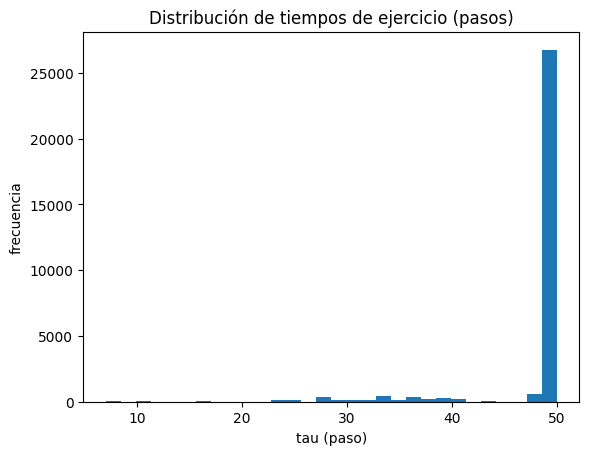

In [9]:

# Parámetros base (ajusta a tu capítulo de resultados)
S0, K, r, q, T = 40.0, 40.0, 0.06, 0.02, 1.0

regime = RegimeParams(
    sigmas=np.array([0.20, 0.35]),
    P=np.array([[0.90, 0.10],
                [0.15, 0.85]])
)
market = MarketParams(r=r, q=q)

n_steps = 50
n_paths = 30000
seed = 42

S, X, Phi, dt = simulate_price_paths_regime_switching(
    S0=S0, K=K, T=T, n_steps=n_steps, n_paths=n_paths,
    regime=regime, market=market, x0=0, seed=seed
)

tau, payoff_tau, betas = lsmc_train_policy(
    S=S, X=X, K=K, r=r, dt=dt,
    basis="laguerre", degree=2,
    min_itm=50
)

price, se, PV = lsmc_price_from_policy(tau, payoff_tau, r=r, dt=dt)

early_ex = np.mean(tau < n_steps)
print(f"LSMC price ≈ {price:.6f}  (SE ≈ {se:.6f})")
print(f"% ejercicio antes del vencimiento: {early_ex*100:.2f}%")
print(f"Ejercicio medio (en pasos): {tau.mean():.2f} / {n_steps}")

# Histograma de tiempos de ejercicio
plt.figure()
plt.hist(tau, bins=30)
plt.title("Distribución de tiempos de ejercicio (pasos)")
plt.xlabel("tau (paso)")
plt.ylabel("frecuencia")
plt.show()



# 4) Resultados intermedios “tipo ejemplo”: ver una regresión concreta

Para que el algoritmo sea **interpretable** (y puedas explicarlo en el TFG), aquí hacemos zoom en un tiempo \(t\) y:
- seleccionamos paths vivos e ITM,
- construimos el target \(Y\),
- calculamos la base y los \(\beta\),
- sacamos \(\hat C\),
- y mostramos quién ejerce y quién continúa.

**Nota:** como hay regímenes, lo haremos para un régimen específico.


In [10]:

def inspect_one_step_regression(S, X, tau, payoff_tau, K, r, dt, t, regime_id=0, degree=2, basis="laguerre", n_show=12):
    if basis == "laguerre":
        basis_fn = basis_laguerre
    else:
        basis_fn = basis_poly

    Phi = payoff_call(S, K)

    alive = tau > t
    S_t = S[t, alive]
    X_t = X[t, alive]
    immediate = Phi[t, alive]

    itm = (immediate > 0) & (X_t == regime_id)

    tau_alive = tau[alive]
    payoff_alive = payoff_tau[alive]
    Y_all = np.exp(-r * (tau_alive - t) * dt) * payoff_alive

    if np.sum(itm) < (degree + 2):
        print("Muy pocos puntos para regresión en este régimen/tiempo.")
        return

    A = basis_fn(state_transform(S_t[itm], K), degree=degree)
    beta = ols_fit(A, Y_all[itm])
    C_hat = A @ beta

    df = pd.DataFrame({
        "S_t": S_t[itm],
        "payoff_inmediato": immediate[itm],
        "Y_target (PV en t)": Y_all[itm],
        "C_hat": C_hat,
        "exercise?": (immediate[itm] >= C_hat)
    })

    df = df.sort_values("S_t").head(n_show).reset_index(drop=True)
    print(f"Tiempo t={t}/{S.shape[0]-1} | régimen={regime_id} | puntos ITM usados={np.sum(itm)}")
    print("Coeficientes beta:", beta)
    display(df)

# inspección
inspect_one_step_regression(S, X, tau, payoff_tau, K, r, dt, t=25, regime_id=0, degree=2, basis="laguerre")


Tiempo t=25/50 | régimen=0 | puntos ITM usados=8995
Coeficientes beta: [  9.1751 -43.217   12.52  ]


,S_t,payoff_inmediato,Y_target (PV en t),C_hat,exercise?
0,40.000591,0.000591,0.000000,2.915560,False
1,40.000826,0.000826,5.055199,2.915740,False
2,40.001938,0.001938,0.000000,2.916594,False
3,40.002737,0.002737,0.000000,2.917207,False
4,40.004786,0.004786,0.000000,2.918779,False
5,40.005063,0.005063,7.335377,2.918992,False
6,40.005243,0.005243,6.453890,2.919131,False
7,40.008599,0.008599,1.146401,2.921706,False
8,40.009691,0.009691,0.000000,2.922544,False
9,40.010499,0.010499,0.000000,2.923164,False



## 4.1. “Frontera” de ejercicio aproximada (visual rápida)
Para una fecha fija \(t\), dibujamos en el plano:
- eje x: \(S_t\)
- color: ejercicio vs continuación

No es una frontera perfecta (porque hay regresión y ruido), pero ayuda muchísimo a entender.


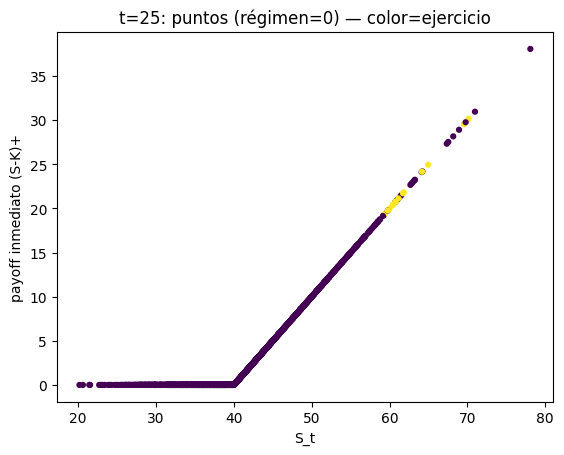

In [11]:

def plot_exercise_scatter(S, X, tau, K, t, regime_id=0, sample=4000, seed=0):
    rng = set_seed(seed)
    M = S.shape[1]
    idx = rng.choice(M, size=min(sample, M), replace=False)

    S_t = S[t, idx]
    X_t = X[t, idx]
    immediate = payoff_call(S_t, K)
    exercise = (tau[idx] == t)

    mask = (X_t == regime_id)

    plt.figure()
    plt.scatter(S_t[mask], immediate[mask], c=exercise[mask], s=12)
    plt.title(f"t={t}: puntos (régimen={regime_id}) — color=ejercicio")
    plt.xlabel("S_t")
    plt.ylabel("payoff inmediato (S-K)+")
    plt.show()

plot_exercise_scatter(S, X, tau, K, t=25, regime_id=0)



# 5) Validación (muy importante en un TFG)

La validación “limpia” es:
1) **apagar regímenes** (poner \(\sigma_L=\sigma_H\) o directamente simular sin X),
2) comparar LSMC contra un **árbol binomial CRR** para call americana con dividend yield continuo.

Si esto cuadra, entonces:
- tu implementación LSMC está bien,
- y ya puedes encender regímenes con tranquilidad (no hay benchmark cerrado, pero sí puedes hacer checks de convergencia).

---

## 5.1. Binomial CRR para call americana con dividend yield \(q\)
Recurrencia:
\[
V_n = \max\Big(\Phi(S_n), e^{-r\Delta t}\big(p V_{n+1}^{up}+(1-p)V_{n+1}^{down}\big)\Big)
\]
con
\[
u=e^{\sigma\sqrt{\Delta t}},\quad d=1/u,\quad p=\frac{e^{(r-q)\Delta t}-d}{u-d}
\]


In [12]:

def crr_american_call(S0: float, K: float, r: float, q: float, sigma: float, T: float, N: int):
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt))
    d = 1.0 / u
    disc = np.exp(-r * dt)
    p = (np.exp((r - q) * dt) - d) / (u - d)

    if not (0 <= p <= 1):
        # ocurre si N es pequeño o parámetros extremos
        raise ValueError(f"p={p:.4f} fuera de [0,1]. Aumenta N o revisa parámetros.")

    # precios al vencimiento
    j = np.arange(N + 1)  # nº de subidas
    S_T = S0 * (u**j) * (d**(N - j))
    V = np.maximum(S_T - K, 0.0)

    # backward
    for n in range(N - 1, -1, -1):
        j = np.arange(n + 1)
        S_n = S0 * (u**j) * (d**(n - j))
        cont = disc * (p * V[1:] + (1 - p) * V[:-1])
        exer = np.maximum(S_n - K, 0.0)
        V = np.maximum(exer, cont)

    return float(V[0])

# benchmark sin regímenes: sigma constante
sigma_const = 0.25
N_tree = 500  # árbol fino para benchmark

price_tree = crr_american_call(S0=S0, K=K, r=r, q=q, sigma=sigma_const, T=T, N=N_tree)
print(f"CRR American Call (sigma={sigma_const}) ≈ {price_tree:.6f}")


CRR American Call (sigma=0.25) ≈ 4.639128



## 5.2. LSMC en el caso sin regímenes (comparación directa con CRR)

Para apagar regímenes, hacemos \(\sigma_L=\sigma_H=\sigma\) y \(P\) da igual.
Luego comparamos.

**Esperable:** LSMC ≈ CRR (diferencias pequeñas que bajan al subir paths y pasos).


In [13]:

# Simulación "sin regímenes": mismas sigmas
regime_const = RegimeParams(
    sigmas=np.array([sigma_const, sigma_const]),
    P=np.array([[0.95, 0.05],
                [0.05, 0.95]])
)

S_c, X_c, Phi_c, dt_c = simulate_price_paths_regime_switching(
    S0=S0, K=K, T=T, n_steps=n_steps, n_paths=n_paths,
    regime=regime_const, market=market, x0=0, seed=seed
)

tau_c, payoff_tau_c, betas_c = lsmc_train_policy(
    S=S_c, X=X_c, K=K, r=r, dt=dt_c,
    basis="laguerre", degree=2, min_itm=50
)
price_lsmc, se_lsmc, PV_lsmc = lsmc_price_from_policy(tau_c, payoff_tau_c, r=r, dt=dt_c)

print(f"LSMC (sigma const) ≈ {price_lsmc:.6f}  (SE ≈ {se_lsmc:.6f})")
print(f"CRR  (sigma const) ≈ {price_tree:.6f}")
print(f"Diferencia LSMC - CRR ≈ {price_lsmc - price_tree:+.6f}")


LSMC (sigma const) ≈ 4.690949  (SE ≈ 0.039379)
CRR  (sigma const) ≈ 4.639128
Diferencia LSMC - CRR ≈ +0.051821



## 5.3. Validación “modelo de regresión”: **in-sample vs out-of-sample**

Este diagnóstico es muy “paper-like”:
- **Train:** ajustas los \(\beta_{t,reg}\) con un conjunto de trayectorias.
- **Test:** simulas nuevas trayectorias y aplicas la policy aprendida (sin re-entrenar).
- Comparas precios in-sample vs out-of-sample: si difieren demasiado → posible overfitting / base mal elegida / pocos ITM.

Aquí lo implementamos de forma clara:
- guardamos `betas[t][reg]`,
- y definimos una función `apply_policy(...)`.


In [14]:

def apply_policy_price(
    S: np.ndarray,
    X: np.ndarray,
    K: float,
    r: float,
    dt: float,
    betas,
    basis: str = "laguerre",
    degree: int = 2
):
    N = S.shape[0] - 1
    M = S.shape[1]
    R = int(X.max()) + 1
    Phi = payoff_call(S, K)

    if basis == "laguerre":
        basis_fn = basis_laguerre
    else:
        basis_fn = basis_poly

    tau = np.full(M, N, dtype=np.int32)
    payoff_tau = Phi[N, :].copy()

    for t in range(N - 1, 0, -1):
        alive = tau > t
        if not np.any(alive):
            continue

        S_t = S[t, alive]
        X_t = X[t, alive]
        immediate = Phi[t, alive]
        itm = immediate > 0
        if not np.any(itm):
            continue

        # Calcula C_hat usando betas ya entrenados (si no hay beta para un régimen, fallback media)
        C_hat = np.zeros_like(immediate)

        betas_t = betas[t]
        if betas_t is None:
            # si no se entrenó en ese t, no ejerces
            continue

        for rg in range(R):
            idx = itm & (X_t == rg)
            if not np.any(idx):
                continue
            beta = betas_t.get(rg, None)
            if beta is None:
                # fallback: continuas
                C_hat[idx] = np.inf
            else:
                A = basis_fn(state_transform(S_t[idx], K), degree=degree)
                C_hat[idx] = A @ beta

        exercise = itm & (immediate >= C_hat)
        alive_idx_global = np.where(alive)[0]
        tau[alive_idx_global[exercise]] = t
        payoff_tau[alive_idx_global[exercise]] = immediate[exercise]

    price, se, PV = lsmc_price_from_policy(tau, payoff_tau, r=r, dt=dt)
    return price, se, tau

# Train
S_train, X_train, _, dt_train = simulate_price_paths_regime_switching(
    S0=S0, K=K, T=T, n_steps=n_steps, n_paths=25000,
    regime=regime, market=market, x0=0, seed=101
)
tau_tr, payoff_tr, betas_tr = lsmc_train_policy(
    S_train, X_train, K, r, dt_train, basis="laguerre", degree=2, min_itm=50
)
price_in, se_in, _ = lsmc_price_from_policy(tau_tr, payoff_tr, r=r, dt=dt_train)

# Test
S_test, X_test, _, dt_test = simulate_price_paths_regime_switching(
    S0=S0, K=K, T=T, n_steps=n_steps, n_paths=25000,
    regime=regime, market=market, x0=0, seed=202
)
price_out, se_out, tau_out = apply_policy_price(
    S_test, X_test, K, r, dt_test, betas_tr, basis="laguerre", degree=2
)

print(f"In-sample  ≈ {price_in:.6f} (SE {se_in:.6f})")
print(f"Out-sample ≈ {price_out:.6f} (SE {se_out:.6f})")
print(f"Diferencia out - in ≈ {price_out - price_in:+.6f}")
print(f"% ejercicio temprano (test): {np.mean(tau_out < n_steps)*100:.2f}%")


In-sample  ≈ 4.823343 (SE 0.045430)
Out-sample ≈ 4.813175 (SE 0.044694)
Diferencia out - in ≈ -0.010169
% ejercicio temprano (test): 15.55%



# 6) Importance Sampling (IS) — cambio de medida + likelihood ratio

**Meta:** reducir varianza cuando el payoff depende de eventos relativamente raros
(por ejemplo, opciones inicialmente OTM o con fuerte dependencia de colas).

## 6.1. Idea operativa en este notebook
En cada paso simulamos innovaciones normales **desplazadas**:
$$
Z_{n}^{(Q)} \sim \mathcal N(\theta\sqrt{\Delta t}, 1)
$$
Esto desplaza la distribución de $S$ hacia valores más altos (si $\theta>0$),
lo que suele ayudar en **calls** inicialmente OTM.

Para mantener el estimador **no sesgado**, cada trayectoria lleva un peso (likelihood ratio)
$$
L_{0\to n}=\prod_{k=1}^{n}\exp\left(-\theta\sqrt{\Delta t}\,Z_{k}^{(Q)}+\tfrac12\theta^2\Delta t\right)
$$
y, en general,
$$
\mathbb E_P[\cdot]=\mathbb E_Q[\cdot\,L]
$$

---

### Importante en americanas (LSMC + IS)
En LSMC necesitamos estimar **condicionales** $E_P[\cdot\mid S_t,X_t]$.
Bajo IS:
$$
E_P[\,\text{cashflow}_\tau \mid \mathcal F_t]=E_Q[\,\text{cashflow}_\tau \, L_{t\to \tau}\mid \mathcal F_t]
$$
Por eso, en la regresión a tiempo \(t\) usamos como target:
$$
Y_i = e^{-r(\tau_i-t)\Delta t}\,\Phi(S_{\tau_i}^{(i)}) \cdot L^{(i)}_{t\to \tau_i}
$$
donde $L_{t\to \tau}=L_{0\to \tau}/L_{0\to t}$.



In [15]:

def simulate_paths_with_importance_sampling(
    S0: float,
    K: float,
    T: float,
    n_steps: int,
    n_paths: int,
    regime: RegimeParams,
    market: MarketParams,
    theta: float,          # intensidad del shift (por unidad de tiempo)
    x0: int = 0,
    seed: int = 123
):
    """
    Simula bajo medida Q_theta:
      Z ~ N(theta*sqrt(dt), 1) en cada paso
    y devuelve además logL acumulado por tiempo:
      logL[t,i] = log L_{0->t} de la trayectoria i.
    """
    validate_params(regime, market)
    rng = set_seed(seed)
    dt = T / n_steps

    # regímenes
    X = simulate_markov_regimes(regime.P, n_steps=n_steps, n_paths=n_paths, x0=x0, rng=rng)

    # innovaciones bajo Q
    Z = rng.normal(loc=theta * np.sqrt(dt), scale=1.0, size=(n_steps, n_paths))

    # log-likelihood ratio acumulado
    # por paso: log(dP/dQ) = -theta*sqrt(dt)*Z + 0.5*theta^2*dt
    logLR_step = (-theta * np.sqrt(dt) * Z) + (0.5 * theta**2 * dt)

    logL = np.zeros((n_steps + 1, n_paths), dtype=np.float64)
    logL[1:, :] = np.cumsum(logLR_step, axis=0)

    # precios
    S = np.empty((n_steps + 1, n_paths), dtype=np.float64)
    S[0, :] = S0
    for t in range(n_steps):
        sigma_t = regime.sigmas[X[t, :]]
        drift = (market.r - market.q - 0.5 * sigma_t**2) * dt
        diff  = sigma_t * np.sqrt(dt) * Z[t, :]
        S[t + 1, :] = S[t, :] * np.exp(drift + diff)

    Phi = payoff_call(S, K)
    return S, X, Phi, logL, dt

print("OK — simulación con IS lista")


OK — simulación con IS lista


In [16]:
def lsmc_train_policy_with_is(
    S: np.ndarray,
    X: np.ndarray,
    logL: np.ndarray,       # logL[t,i] = log L_{0->t}
    K: float,
    r: float,
    dt: float,
    basis: str = "laguerre",
    degree: int = 2,
    min_itm: int = 30
):
    """
    Entrena policy LSMC usando datos simulados bajo Q (IS),
    estimando continuaciones bajo P mediante targets ponderados L_{t->tau}.

    Target a tiempo t (para cada trayectoria viva i):
      Y_i = exp(-r (tau_i - t) dt) * payoff_tau_i * L_{t->tau_i}(i)
    donde L_{t->tau} = exp(logL[tau,i] - logL[t,i]).

    Nota numérica: regresión en x = S/K.
    """
    N = S.shape[0] - 1
    M = S.shape[1]
    R = int(X.max()) + 1
    Phi = payoff_call(S, K)

    if basis == "laguerre":
        basis_fn = basis_laguerre
    else:
        basis_fn = basis_poly

    tau = np.full(M, N, dtype=np.int32)
    payoff_tau = Phi[N, :].copy()

    betas = [None] * (N + 1)

    for t in range(N - 1, 0, -1):
        alive = tau > t
        if not np.any(alive):
            continue

        gidx = np.where(alive)[0]          # índices globales de trayectorias vivas
        S_t = S[t, alive]
        X_t = X[t, alive]
        immediate = Phi[t, alive]
        itm = immediate > 0

        if np.sum(itm) < min_itm:
            continue

        tau_alive = tau[alive]
        payoff_alive = payoff_tau[alive]

        # L_{t->tau} = exp(logL[tau, i] - logL[t, i])
        L_t_to_tau = np.exp(logL[tau_alive, gidx] - logL[t, gidx])

        Y = np.exp(-r * (tau_alive - t) * dt) * payoff_alive * L_t_to_tau

        betas_t = {}
        C_hat = np.zeros_like(immediate)

        x_t = state_transform(S_t, K)

        for rg in range(R):
            idx = itm & (X_t == rg)
            if np.sum(idx) == 0:
                continue
            if np.sum(idx) < (degree + 2):
                C_hat[idx] = np.mean(Y[idx])
                betas_t[rg] = None
                continue
            A = basis_fn(x_t[idx], degree=degree)
            beta = ols_fit(A, Y[idx])
            C_hat[idx] = A @ beta
            betas_t[rg] = beta

        betas[t] = betas_t

        exercise = itm & (immediate >= C_hat)
        tau[gidx[exercise]] = t
        payoff_tau[gidx[exercise]] = immediate[exercise]

    return tau, payoff_tau, betas

def is_price_from_policy(tau: np.ndarray, payoff_tau: np.ndarray, logL: np.ndarray, r: float, dt: float):
    """
    Precio bajo P estimado con paths simulados bajo Q:
        V0 = E_Q[ exp(-r tau dt) payoff_tau * L_{0->tau} ]
    donde L_{0->tau} = exp(logL[tau,i]).
    """
    idx = np.arange(len(tau))
    weights = np.exp(logL[tau, idx])
    PVw = np.exp(-r * tau * dt) * payoff_tau * weights

    price = PVw.mean()
    se = PVw.std(ddof=1) / np.sqrt(len(PVw))
    return price, se, PVw

print("OK — LSMC + IS (entreno y pricing) listo")

OK — LSMC + IS (entreno y pricing) listo



## 6.2. Comparación práctica: sin IS vs con IS

Hacemos un ejemplo donde IS suele ayudar: una call **ligeramente OTM** o con baja probabilidad de ITM.

- Sin IS: simulación estándar $Z\sim N(0,1)$.
- Con IS: desplazamos con $\theta>0$.

Mostramos precios y errores estándar estimados.


In [17]:

# Caso algo OTM para que IS tenga sentido
S0_is, K_is, T_is = 38.0, 45.0, 1.0
n_steps_is, n_paths_is = 60, 40000
theta = 0.8  # prueba inicial (luego lo afinamos)

# Sin IS (simulación estándar + LSMC estándar)
S_std, X_std, _, dt_std = simulate_price_paths_regime_switching(
    S0=S0_is, K=K_is, T=T_is, n_steps=n_steps_is, n_paths=n_paths_is,
    regime=regime, market=market, x0=0, seed=11
)
tau_std, payoff_std, betas_std = lsmc_train_policy(
    S_std, X_std, K_is, r, dt_std, basis="laguerre", degree=2, min_itm=40
)
price_std, se_std, _ = lsmc_price_from_policy(tau_std, payoff_std, r=r, dt=dt_std)

# Con IS
S_is, X_is, _, logL, dt_is = simulate_paths_with_importance_sampling(
    S0=S0_is, K=K_is, T=T_is, n_steps=n_steps_is, n_paths=n_paths_is,
    regime=regime, market=market, theta=theta, x0=0, seed=11
)
tau_is, payoff_is, betas_is = lsmc_train_policy_with_is(
    S_is, X_is, logL, K_is, r, dt_is, basis="laguerre", degree=2, min_itm=40
)
price_is, se_is, _ = is_price_from_policy(tau_is, payoff_is, logL, r=r, dt=dt_is)

print(f"Sin IS:  price ≈ {price_std:.6f} (SE {se_std:.6f})")
print(f"Con IS:  price ≈ {price_is:.6f} (SE {se_is:.6f}) | theta={theta}")
print(f"Ratio SE(IS)/SE(std) ≈ {se_is/se_std:.3f}")


Sin IS:  price ≈ 2.104794 (SE 0.023459)
Con IS:  price ≈ 2.120791 (SE 0.011583) | theta=0.8
Ratio SE(IS)/SE(std) ≈ 0.494



## 6.3. (Opcional pero muy TFG) Ajuste de \(\theta\) por búsqueda sencilla

En un TFG queda muy bien mostrar que:
- IS depende de un parámetro,
- y que lo eliges con un criterio objetivo (minimizar varianza estimada en una fase piloto).

Aquí hacemos una búsqueda en rejilla y devolvemos el $\theta$ que minimiza el error estándar.


In [18]:

def tune_theta_grid(
    thetas,
    S0: float, K: float, T: float,
    n_steps: int, n_paths_pilot: int,
    regime: RegimeParams, market: MarketParams,
    seed: int = 0
):
    rows = []
    for th in thetas:
        S_is, X_is, _, logL, dt = simulate_paths_with_importance_sampling(
            S0=S0, K=K, T=T, n_steps=n_steps, n_paths=n_paths_pilot,
            regime=regime, market=market, theta=th, x0=0, seed=seed
        )
        tau, payoff_tau, _ = lsmc_train_policy_with_is(
            S_is, X_is, logL, K, market.r, dt, basis="laguerre", degree=2, min_itm=30
        )
        price, se, _ = is_price_from_policy(tau, payoff_tau, logL, market.r, dt)
        rows.append({"theta": th, "price": price, "se": se})
    df = pd.DataFrame(rows).sort_values("se")
    return df

thetas = np.linspace(0.0, 1.5, 10)
df_theta = tune_theta_grid(
    thetas=thetas,
    S0=S0_is, K=K_is, T=T_is,
    n_steps=n_steps_is, n_paths_pilot=12000,
    regime=regime, market=market,
    seed=77
)

display(df_theta)
best = df_theta.iloc[0]
print(f"Mejor theta (piloto) ≈ {best['theta']:.3f} con SE ≈ {best['se']:.6f}")


,theta,price,se
9,1.500000,2.100798,0.015306
8,1.333333,2.106337,0.015684
7,1.166667,2.103356,0.016678
6,1.000000,2.098687,0.018346
5,0.833333,2.096140,0.020631
4,0.666667,2.092253,0.023508
3,0.500000,2.091060,0.027025
2,0.333333,2.081919,0.031144
1,0.166667,2.078530,0.036585
0,0.000000,2.109259,0.045342


Mejor theta (piloto) ≈ 1.500 con SE ≈ 0.015306


In [27]:
import time
import numpy as np
import pandas as pd

def run_lsm_standard_case(S0, K, r, q, T, n_steps, n_paths, regime, x0=0, seed=0,
                          basis="laguerre", degree=2, min_itm=50):
    market = MarketParams(r=r, q=q)

    t0 = time.perf_counter()
    S, X, _, dt = simulate_price_paths_regime_switching(
        S0=S0, K=K, T=T, n_steps=n_steps, n_paths=n_paths,
        regime=regime, market=market, x0=x0, seed=seed
    )
    t1 = time.perf_counter()

    tau, payoff_tau, _ = lsmc_train_policy(
        S=S, X=X, K=K, r=r, dt=dt,
        basis=basis, degree=degree, min_itm=min_itm
    )
    t2 = time.perf_counter()

    price, se, _ = lsmc_price_from_policy(tau, payoff_tau, r=r, dt=dt)
    early = float(np.mean(tau < n_steps))
    tau_mean = float(np.mean(tau))

    return {
        "price": float(price),
        "se": float(se),
        "early_%": 100.0 * early,
        "tau_mean": tau_mean,
        "t_sim_s": t1 - t0,
        "t_train_s": t2 - t1,
        "t_total_s": t2 - t0
    }

def run_lsm_is_case(S0, K, r, q, T, n_steps, n_paths, regime, theta, x0=0, seed=0,
                    basis="laguerre", degree=2, min_itm=50):
    market = MarketParams(r=r, q=q)

    t0 = time.perf_counter()
    S, X, _, logL, dt = simulate_paths_with_importance_sampling(
        S0=S0, K=K, T=T, n_steps=n_steps, n_paths=n_paths,
        regime=regime, market=market, theta=theta, x0=x0, seed=seed
    )
    t1 = time.perf_counter()

    tau, payoff_tau, _ = lsmc_train_policy_with_is(
        S=S, X=X, logL=logL, K=K, r=r, dt=dt,
        basis=basis, degree=degree, min_itm=min_itm
    )
    t2 = time.perf_counter()

    price, se, _ = is_price_from_policy(tau, payoff_tau, logL=logL, r=r, dt=dt)
    early = float(np.mean(tau < n_steps))
    tau_mean = float(np.mean(tau))

    return {
        "price": float(price),
        "se": float(se),
        "early_%": 100.0 * early,
        "tau_mean": tau_mean,
        "t_sim_s": t1 - t0,
        "t_train_s": t2 - t1,
        "t_total_s": t2 - t0
    }

def df_to_latex_file(df, path_tex, float_fmt="%.4f"):
    tex = df.to_latex(index=False, escape=True,
                      float_format=lambda x: float_fmt % x)
    with open(path_tex, "w", encoding="utf-8") as f:
        f.write(tex)
    return tex



In [28]:
# Parámetros de validación (ajusta si quieres)
S0, K, r, q, T = 40.0, 40.0, 0.06, 0.02, 1.0
sigma_const = 0.25

# Árbol CRR
N_tree = 500
price_crr = crr_american_call(S0=S0, K=K, r=r, q=q, sigma=sigma_const, T=T, N=N_tree)

# LSMC con sigma constante (lo represento como "sin regímenes": sigmas iguales)
regime_const = RegimeParams(
    sigmas=np.array([sigma_const, sigma_const]),
    P=np.array([[0.95, 0.05],
                [0.05, 0.95]])
)

out = run_lsm_standard_case(
    S0=S0, K=K, r=r, q=q, T=T,
    n_steps=50, n_paths=30000,
    regime=regime_const, x0=0, seed=42,
    basis="laguerre", degree=2, min_itm=50
)

df_val = pd.DataFrame([{
    "Metodo": "CRR (binomial)",
    "Precio": price_crr,
    "SE": np.nan,
    "Ejercicio temprano (%)": np.nan
},{
    "Metodo": "LSMC (MC)",
    "Precio": out["price"],
    "SE": out["se"],
    "Ejercicio temprano (%)": out["early_%"]
}])

print(df_val)
df_to_latex_file(df_val, "tabla_validacion_crr_lsmc.tex")


           Metodo    Precio        SE  Ejercicio temprano (%)
0  CRR (binomial)  4.639128       NaN                     NaN
1       LSMC (MC)  4.690949  0.039379               11.693333


'\\begin{tabular}{lrrr}\n\\toprule\nMetodo & Precio & SE & Ejercicio temprano (\\%) \\\\\n\\midrule\nCRR (binomial) & 4.6391 & NaN & NaN \\\\\nLSMC (MC) & 4.6909 & 0.0394 & 11.6933 \\\\\n\\bottomrule\n\\end{tabular}\n'

In [29]:
# Parámetros de tu modelo con regímenes
regime = RegimeParams(
    sigmas=np.array([0.20, 0.35]),
    P=np.array([[0.90, 0.10],
                [0.15, 0.85]])
)

r, q = 0.06, 0.02
K = 40.0
T = 1.0
n_steps = 50
n_paths = 30000

scenarios = [
    {"tag": "OTM", "S0": 36.0},
    {"tag": "ATM", "S0": 40.0},
    {"tag": "ITM", "S0": 44.0},
]

rows = []
for sc in scenarios:
    for x0 in [0, 1]:
        out = run_lsm_standard_case(
            S0=sc["S0"], K=K, r=r, q=q, T=T,
            n_steps=n_steps, n_paths=n_paths,
            regime=regime, x0=x0, seed=42,
            basis="laguerre", degree=2, min_itm=50
        )
        rows.append({
            "Moneyness": sc["tag"],
            "S0": sc["S0"],
            "x0 (regimen inicial)": x0,
            "Precio (LSMC)": out["price"],
            "SE": out["se"],
            "Ejercicio temprano (%)": out["early_%"],
            "tau medio (pasos)": out["tau_mean"],
        })

df_main = pd.DataFrame(rows)
print(df_main)
df_to_latex_file(df_main, "tabla_resultados_regimenes.tex")


  Moneyness    S0  x0 (regimen inicial)  Precio (LSMC)        SE  Ejercicio temprano (%)  tau medio (pasos)
0       OTM  36.0                     0       2.786951  0.030281                9.593333          48.957767
1       OTM  36.0                     1       2.965647  0.031924                9.730000          48.804600
2       ATM  40.0                     0       4.890442  0.040752               14.420000          48.373800
3       ATM  40.0                     1       5.090528  0.043007               13.853333          48.379800
4       ITM  44.0                     0       7.566125  0.051053               19.003333          47.866467
5       ITM  44.0                     1       7.758111  0.053621               16.583333          47.867667


'\\begin{tabular}{lrrrrrr}\n\\toprule\nMoneyness & S0 & x0 (regimen inicial) & Precio (LSMC) & SE & Ejercicio temprano (\\%) & tau medio (pasos) \\\\\n\\midrule\nOTM & 36.0000 & 0 & 2.7870 & 0.0303 & 9.5933 & 48.9578 \\\\\nOTM & 36.0000 & 1 & 2.9656 & 0.0319 & 9.7300 & 48.8046 \\\\\nATM & 40.0000 & 0 & 4.8904 & 0.0408 & 14.4200 & 48.3738 \\\\\nATM & 40.0000 & 1 & 5.0905 & 0.0430 & 13.8533 & 48.3798 \\\\\nITM & 44.0000 & 0 & 7.5661 & 0.0511 & 19.0033 & 47.8665 \\\\\nITM & 44.0000 & 1 & 7.7581 & 0.0536 & 16.5833 & 47.8677 \\\\\n\\bottomrule\n\\end{tabular}\n'

In [30]:
# Caso OTM típico para IS
S0_is, K_is, T_is = 38.0, 45.0, 1.0
n_steps_is, n_paths_is = 60, 40000
theta = 0.8  # o el que te salga mejor en piloto

out_std = run_lsm_standard_case(
    S0=S0_is, K=K_is, r=r, q=q, T=T_is,
    n_steps=n_steps_is, n_paths=n_paths_is,
    regime=regime, x0=0, seed=11,
    basis="laguerre", degree=2, min_itm=50
)

out_is = run_lsm_is_case(
    S0=S0_is, K=K_is, r=r, q=q, T=T_is,
    n_steps=n_steps_is, n_paths=n_paths_is,
    regime=regime, theta=theta, x0=0, seed=11,
    basis="laguerre", degree=2, min_itm=50
)

df_is = pd.DataFrame([{
    "Metodo": "LSMC (std)",
    "Precio": out_std["price"],
    "SE": out_std["se"],
    "Ejercicio temprano (%)": out_std["early_%"]
},{
    "Metodo": f"LSMC + IS (theta={theta})",
    "Precio": out_is["price"],
    "SE": out_is["se"],
    "Ejercicio temprano (%)": out_is["early_%"]
}])

df_is["Ratio_SE_vs_std"] = [np.nan, df_is.loc[1, "SE"]/df_is.loc[0, "SE"]]

print(df_is)
df_to_latex_file(df_is, "tabla_is_vs_std.tex")


                  Metodo    Precio        SE  Ejercicio temprano (%)  Ratio_SE_vs_std
0             LSMC (std)  2.104794  0.023459                   8.380              NaN
1  LSMC + IS (theta=0.8)  2.120791  0.011583                  16.775         0.493765


'\\begin{tabular}{lrrrr}\n\\toprule\nMetodo & Precio & SE & Ejercicio temprano (\\%) & Ratio\\_SE\\_vs\\_std \\\\\n\\midrule\nLSMC (std) & 2.1048 & 0.0235 & 8.3800 & NaN \\\\\nLSMC + IS (theta=0.8) & 2.1208 & 0.0116 & 16.7750 & 0.4938 \\\\\n\\bottomrule\n\\end{tabular}\n'

In [31]:
thetas = np.linspace(0.0, 1.2, 7)  # rejilla pequeña y explicable en el TFG
n_paths_pilot = 12000

rows = []
for th in thetas:
    out = run_lsm_is_case(
        S0=S0_is, K=K_is, r=r, q=q, T=T_is,
        n_steps=n_steps_is, n_paths=n_paths_pilot,
        regime=regime, theta=float(th), x0=0, seed=123,
        basis="laguerre", degree=2, min_itm=50
    )
    rows.append({"theta": float(th), "price": out["price"], "se": out["se"]})

df_theta = pd.DataFrame(rows).sort_values("se")
print(df_theta)

theta_star = float(df_theta.iloc[0]["theta"])
print("theta* (min SE piloto) =", theta_star)
df_to_latex_file(df_theta, "tabla_piloto_theta.tex")


   theta     price        se
6    1.2  2.087087  0.015990
5    1.0  2.089029  0.018052
4    0.8  2.106000  0.021033
3    0.6  2.119076  0.024861
2    0.4  2.122377  0.029512
1    0.2  2.131716  0.035771
0    0.0  2.124627  0.042741
theta* (min SE piloto) = 1.2


'\\begin{tabular}{rrr}\n\\toprule\ntheta & price & se \\\\\n\\midrule\n1.2000 & 2.0871 & 0.0160 \\\\\n1.0000 & 2.0890 & 0.0181 \\\\\n0.8000 & 2.1060 & 0.0210 \\\\\n0.6000 & 2.1191 & 0.0249 \\\\\n0.4000 & 2.1224 & 0.0295 \\\\\n0.2000 & 2.1317 & 0.0358 \\\\\n0.0000 & 2.1246 & 0.0427 \\\\\n\\bottomrule\n\\end{tabular}\n'